In [19]:
import numpy as np
import pandas as pd
import glob
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patheffects as pe
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib.ticker import LogLocator, LogFormatter
from matplotlib.ticker import LogLocator, NullFormatter
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Ellipse
from mpl_toolkits.axes_grid1 import make_axes_locatable
from io import StringIO
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
from constants import *
from functions import *

from scipy.stats import linregress

In [21]:
def R0(v_w, Mdot, v_st, n_ISM, mu_ISM, T_ISM):
    
    alpha_ISM = kB*T_ISM/(v_st**2. * mp * mu_ISM)
    rho_ISM = mp*n_ISM*mu_ISM
    
    R0 = np.sqrt(v_w*Mdot / (4.*np.pi*(1.+alpha_ISM)*rho_ISM*v_st**2.) )
    
    return R0

In [22]:
def R0_proj(R0, distance, incli):
    '''
    Angular distance in arcmin
    '''
    
    R0_proj = (R0/AU)/(distance/pc)/60.*np.cos(incli)
    return R0_proj

In [23]:
cmap = 'viridis'

# BD+60

In [24]:
ang_corr_deg = 28.
ang_corr = np.deg2rad(ang_corr_deg)
cosd = 0.4819
inclination_deg = 56.
inclination = np.deg2rad(inclination_deg)
incli = np.pi/2. - inclination

In [25]:
v_st = 42e5
n_ISM = 27.
mu_ISM = 0.615
T_ISM = 8e3
v_w = 2000e5
Mdot = 1.3e-6*Msun_yr
distance = 2.99*kpc

In [26]:
R0_BD60 = R0(v_w, Mdot, v_st, n_ISM, mu_ISM, T_ISM)
R0_proj_BD60 = R0_proj(R0_BD60, distance, incli)

print(R0_BD60, R0_proj_BD60)

1.5839756073286497e+18 0.48931189269086484


In [27]:
source_file = '../../../R0_proj_BD+60.dat'

## Avg 4-12 GHz

In [28]:
nu_avg_file = '../../../SW_conv_avgabs_BD+60.dat'

In [29]:
contour_levels = [0.5, 1., 1.5, 3.]
 
xlim = (-2, 2)
ylim = (-1.5, 1.5)
 
# beam size
siz_x = 10. / 60.0
siz_y = 20. / 60.0

In [30]:
X, Y, Z = load_gridded_data(nu_avg_file)
Xr, Yr = rotate(X, Y, ang_corr, sign=+1)
 
try:
    src = np.atleast_2d(np.loadtxt(source_file))
    xs, ys = rotate(src[:, 0], src[:, 1], ang_corr, sign=-1)
except OSError:
    xs, ys = np.array([]), np.array([])
    
xs, ys = xs*np.cos(incli), ys*np.cos(incli)
x0_proj_corr = R0_proj_BD60 * np.sin(-ang_corr)
y0_proj_corr = R0_proj_BD60 * np.cos(ang_corr)

<ipython-input-31-f54bbad587dc>:11: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax3.scatter(xs, ys, s=200, marker='+', facecolor='cyan',


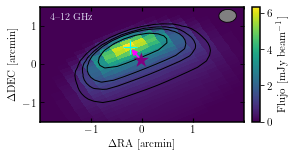

In [31]:
fig3, ax3 = plt.subplots(figsize=(0.6*text_width, 2./3.*0.6*text_width))
 
mesh = ax3.pcolormesh(Xr, Yr, Z, cmap=cmap, shading='auto')
mesh.set_rasterized(True)
 
# contours
cs = ax3.contour(Xr, Yr, Z, levels=contour_levels, colors='black', linewidths=1.)

if xs.size:
    ax3.scatter(xs, ys, s=200, marker='+', facecolor='cyan',
                edgecolor='black', linewidth=1.2, zorder=5)

ax3.annotate(
    '', xy=(x0_proj_corr, y0_proj_corr), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='magenta', lw=1.8),
    zorder=6,
)
 
# star marker
ax3.scatter([-0.01], [0.1], s=260, marker='*', facecolor='purple',
           edgecolor='none', zorder=6)
 
# beam ellipse
xlo, xhi = xlim
ylo, yhi = ylim
gx, gy = 0.92, 0.92  # ax fraction position
cx = xlo + gx * (xhi - xlo)
cy = ylo + gy * (yhi - ylo)
 
beam = Ellipse(
    (cx, cy),
    width=siz_x / cosd,
    height=siz_y,
    angle=ang_corr_deg,
    facecolor='grey', edgecolor='black', lw=0.8, zorder=7,
)
ax3.add_patch(beam)

ax3.text(0.05, 0.9, '4--12 GHz', transform=ax3.transAxes,
        ha='left', va='center', zorder=6, color='lavender')
 
# ----------------------------------------------------------------------
# Axes and limits
# ----------------------------------------------------------------------
ax3.set_xlim(*xlim)
ax3.set_ylim(*ylim)
ax3.set_xlabel(r'$\Delta$RA [arcmin]')
ax3.set_ylabel(r'$\Delta$DEC [arcmin]')
 
ax3.set_aspect((xhi - xlo) / (yhi - ylo) * (3. / 4.0) *
              ((yhi - ylo) / (xhi - xlo)))
 
ax3.xaxis.set_major_locator(plt.MultipleLocator(5))
ax3.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax3.yaxis.set_major_locator(plt.MultipleLocator(5))
ax3.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax3.set_xticks([-1,0,1])
ax3.set_yticks([-1,0,1])
ax3.tick_params(which='both', direction='in', top=True, right=True)

fig3.canvas.draw()
pos = ax3.get_position()
cbar_width = 0.03
cbar_pad = 0.03
cbar_corr = 0.0
cax = fig3.add_axes([pos.x1 + cbar_pad, pos.y0 + cbar_corr, cbar_width, pos.height])
cbar = fig3.colorbar(mesh, cax=cax)
cbar.set_label('Flujo [mJy beam$^{-1}$]')

plt.show()


## 110 MHz

In [32]:
nu_110_file = '../../../SW_conv_110MHzabs_BD+60.dat'

In [33]:
contour_levels = [0.5, 1, 1.75]
 
xlim = (-2, 2)
ylim = (-1.5, 1.5)
 
siz_x = 4. / 60.0
siz_y = 4. / 60.0

In [34]:
X, Y, Z = load_gridded_data(nu_110_file)
Xr, Yr = rotate(X, Y, ang_corr, sign=+1)

try:
    src = np.atleast_2d(np.loadtxt(source_file))
    xs, ys = rotate(src[:, 0], src[:, 1], ang_corr, sign=-1)
except OSError:
    xs, ys = np.array([]), np.array([])
    
xs, ys = xs*np.cos(incli), ys*np.cos(incli)
x0_proj_corr = R0_proj_BD60 * np.sin(-ang_corr)
y0_proj_corr = R0_proj_BD60 * np.cos(ang_corr)

<ipython-input-35-b68bf7119803>:11: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('+').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax4.scatter(xs, ys, s=200, marker='+', facecolor='cyan',


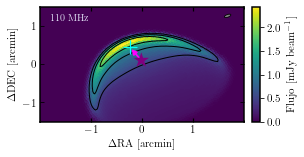

In [35]:
fig4, ax4 = plt.subplots(figsize=(0.6*text_width, 2./3.*0.6*text_width))
 
mesh = ax4.pcolormesh(Xr, Yr, Z, cmap=cmap, shading='auto')
mesh.set_rasterized(True)
 
cs = ax4.contour(Xr, Yr, Z, levels=contour_levels, colors='black', linewidths=1.)

if xs.size:
    ax4.scatter(xs, ys, s=200, marker='+', facecolor='cyan',
                edgecolor='black', linewidth=1.2, zorder=5)

ax4.annotate(
    '', xy=(x0_proj_corr, y0_proj_corr), xytext=(-0.01, 0.1),
    arrowprops=dict(arrowstyle='-|>', color='magenta', lw=1.8),
    zorder=6,
)

ax4.scatter([-0.01], [0.1], s=260, marker='*', facecolor='purple',
           edgecolor='none', zorder=6)

xlo, xhi = xlim
ylo, yhi = ylim
gx, gy = 0.92, 0.92
cx = xlo + gx * (xhi - xlo)
cy = ylo + gy * (yhi - ylo)
 
beam = Ellipse(
    (cx, cy),
    width=siz_x / cosd,
    height=siz_y,
    angle=ang_corr_deg,
    facecolor='grey', edgecolor='black', lw=0.8, zorder=7,
)
ax4.add_patch(beam)

ax4.text(0.05, 0.9, '110 MHz', transform=ax4.transAxes,
        ha='left', va='center', zorder=6, color='lavender')
 
ax4.set_xlim(*xlim)
ax4.set_ylim(*ylim)
ax4.set_xlabel(r'$\Delta$RA [arcmin]')
ax4.set_ylabel(r'$\Delta$DEC [arcmin]')
 
ax4.set_aspect((xhi - xlo) / (yhi - ylo) * (3. / 4.0) *
              ((yhi - ylo) / (xhi - xlo)))
 
ax4.xaxis.set_major_locator(plt.MultipleLocator(5))
ax4.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax4.yaxis.set_major_locator(plt.MultipleLocator(5))
ax4.yaxis.set_minor_locator(plt.MultipleLocator(1))
ax4.set_xticks([-1,0,1])
ax4.set_yticks([-1,0,1])
ax4.tick_params(which='both', direction='in', top=True, right=True)

fig4.canvas.draw()
pos = ax4.get_position()
cbar_width = 0.03
cbar_pad = 0.03
cbar_corr = 0.0
cax = fig4.add_axes([pos.x1 + cbar_pad, pos.y0 + cbar_corr, cbar_width, pos.height])
cbar = fig4.colorbar(mesh, cax=cax)
cbar.set_label('Flujo [mJy beam$^{-1}$]')

plt.show()


# Save figs

In [36]:
from matplotlib.transforms import Bbox

def tight_bbox(fig, pad=0.01):
    bbox = fig.get_tightbbox(fig.canvas.get_renderer())
    return bbox.padded(pad)

bbox3 = tight_bbox(fig3)
bbox4 = tight_bbox(fig4)

common_bbox = Bbox.union([bbox3, bbox4])


fig3.savefig('map_BD+60_avg.pdf',  bbox_inches=common_bbox)
fig4.savefig('map_BD+60_110M.pdf',  bbox_inches=common_bbox)